# EDA ASL-Sensor-Dataglove

Для работы взят датасет ASL (американского жестового языка) из статьи https://www.nature.com/articles/s41598-022-25108-2 

В ноутбуке рассмотрены первые три этапа EDA:

1. Структура архива, описание каналов и метаданные исполнений.
2. Основные статистики, баланс классов и пользователей.
3. Пропуски, временные ошибки, некорректные значения и возможные выбросы.

## Подготовка

Загружаем нужные библиотеки и задаем базовые параметры

In [1]:
from pathlib import Path, PurePosixPath
from collections import Counter
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import median_filter
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})
plot_color = sns.color_palette("deep")[0]
archive_path = Path("ASL-Sensor-Dataglove-Dataset.zip")

## 1. Структура датасета и метаданные

### 1.1. Содержимое архива

In [2]:
with ZipFile(archive_path) as archive:
    csv_paths = sorted(name for name in archive.namelist()
        if name.startswith("ASL-Sensor-Dataglove-Dataset/") and name.endswith(".csv"))

subjects = sorted({PurePosixPath(path).parent.name for path in csv_paths})
gestures = sorted({PurePosixPath(path).stem for path in csv_paths})

print("CSV-файлов:", len(csv_paths))
print("Пользователей:", len(subjects))
print("Классов:", len(gestures))

CSV-файлов: 1000
Пользователей: 25
Классов: 40


**Вывод.** Внутри ZIP структура соответствует заявленной в статье – 25 пользователей и 40 классов жестов.

### 1.2. Метки и структура каталогов

Папка обозначает пользователя, имя CSV обозначает класс жеста. К буквам относим односимвольные названия, к словам все остальные. Посмотрим, какие классы представлены в датасете.

In [3]:
file_index = pd.DataFrame({
    "source_file": csv_paths,
    "subject_id": [PurePosixPath(path).parent.name for path in csv_paths],
    "gesture": [PurePosixPath(path).stem for path in csv_paths],
})
file_index["label_group"] = np.where(file_index["gesture"].str.len() == 1, "Буква", "Слово")

print("Буквы:", sorted(file_index.loc[file_index.label_group == "Буква", "gesture"].unique()))
print("Слова:", sorted(file_index.loc[file_index.label_group == "Слово", "gesture"].unique()))
file_index.sample(13)

Буквы: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Слова: ['bad', 'deaf', 'fine', 'good', 'goodbye', 'hello', 'hungry', 'me', 'no', 'please', 'sorry', 'thankyou', 'yes', 'you']


,source_file,subject_id,gesture,label_group
730,ASL-Sensor-Dataglove-Dataset/019/good.csv,019,good,Слово
702,ASL-Sensor-Dataglove-Dataset/018/no.csv,018,no,Слово
665,ASL-Sensor-Dataglove-Dataset/017/please.csv,017,please,Слово
417,ASL-Sensor-Dataglove-Dataset/011/k.csv,011,k,Буква
680,ASL-Sensor-Dataglove-Dataset/018/a.csv,018,a,Буква
281,ASL-Sensor-Dataglove-Dataset/008/b.csv,008,b,Буква
700,ASL-Sensor-Dataglove-Dataset/018/me.csv,018,me,Слово
171,ASL-Sensor-Dataglove-Dataset/005/goodbye.csv,005,goodbye,Слово
718,ASL-Sensor-Dataglove-Dataset/018/you.csv,018,you,Слово
891,ASL-Sensor-Dataglove-Dataset/023/goodbye.csv,023,goodbye,Слово


### 1.3. Схема сенсорных данных

Прочитаем один CSV, проверим названия столбцов и составим словарь полей.

In [4]:
with ZipFile(archive_path) as archive:
    with archive.open(csv_paths[0]) as file:
        example = pd.read_csv(file, dtype={"user_id": "string"})

sensor_cols = [col for col in example.columns if col not in ["timestamp", "user_id"]]
flex_cols = [f"flex_{i}" for i in range(1, 6)]
quat_cols = ["Qw", "Qx", "Qy", "Qz"]
gyro_cols = ["GYRx", "GYRy", "GYRz"]
acc_cols = ["ACCx", "ACCy", "ACCz"]
body_cols = ["ACCx_body", "ACCy_body", "ACCz_body"]
world_cols = ["ACCx_world", "ACCy_world", "ACCz_world"]

data_dictionary = pd.DataFrame([
    ["timestamp", "Временная метка Unix", "с"],
    ["user_id", "Идентификатор пользователя", "категория"],
    ["flex_1 ... flex_5", "Показания пяти датчиков изгиба", "?"],
    ["Qw, Qx, Qy, Qz", "Кватернион ориентации кисти", "безразмерный"],
    ["GYRx, GYRy, GYRz", "Угловая скорость", "?"],
    ["ACCx, ACCy, ACCz", "Исходное ускорение", "м/с²???"],
    ["ACC*_body", "Ускорение без гравитации в координатах кисти", "м/с²"],
    ["ACC*_world", "Ускорение без гравитации в земных координатах", "м/с²"],
], columns=["Поля", "Описание", "Единицы"])

print("Форма одного CSV:", example.shape)
print("Число сенсорных каналов:", len(sensor_cols))
data_dictionary

Форма одного CSV: (1500, 23)
Число сенсорных каналов: 21


,Поля,Описание,Единицы
0,timestamp,Временная метка Unix,с
1,user_id,Идентификатор пользователя,категория
2,flex_1 ... flex_5,Показания пяти датчиков изгиба,?
3,"Qw, Qx, Qy, Qz",Кватернион ориентации кисти,безразмерный
4,"GYRx, GYRy, GYRz",Угловая скорость,?
5,"ACCx, ACCy, ACCz",Исходное ускорение,м/с²???
6,ACC*_body,Ускорение без гравитации в координатах кисти,м/с²
7,ACC*_world,Ускорение без гравитации в земных координатах,м/с²


flex_1 ... flex_5 -- признаки, собранные с датчиков изгиба

остальные 5 категорий -- признаки, собранные с датчика IMU

### 1.4. Чтение архива и индекс исполнений

Прочитаем все основные CSV. Для каждого файла сохраним количество строк, проверим идентификатор пользователя и выделим исполнения по 150 отсчетов (150 сигналов=произнесение одного жеста). 
Проверим, что все файлы действительно состоят из 1500 строк. После этого отдельно проверим временные границы блоков.

В памяти оставим два уровня данных: исходные измерения `signals` и таблицу отдельных исполнений `trials`.

In [5]:
frames = []
file_rows = []
trial_rows = []
spike_rows = []
within_deltas = []

# задаем типы данных
read_types = {"user_id": "string", **{col: "float32" for col in sensor_cols}}

with ZipFile(archive_path) as archive:
    for path in csv_paths:
        with archive.open(path) as file:
            df = pd.read_csv(file, dtype=read_types)

        subject_id = PurePosixPath(path).parent.name # название папки
        gesture = PurePosixPath(path).stem # название файла
        dt = df["timestamp"].diff() # считаем разницу между текущей меткой и предыдущей
        has_expected_shape = len(df) == 1500 and df.columns.tolist() == example.columns.tolist()
        # совпадают ли айди пользователей в файлах с названием в папке
        csv_ids = set(df["user_id"].dropna().unique())
        raw_id_mismatch = csv_ids != {subject_id}
        id_mismatch = {user.zfill(3) for user in csv_ids} != {subject_id} # докидываем нули в начало, чтобы смэтчить

        # базовые проверки внутри файла
        file_rows.append({
            "source_file": path,
            "subject_id": subject_id,
            "gesture": gesture,
            "n_rows": len(df),
            "n_columns": df.shape[1],
            "expected_shape": has_expected_shape,
            "raw_id_mismatch": raw_id_mismatch,
            "id_mismatch_after_format": id_mismatch,
            "missing_cells": int(df.isna().sum().sum()),
            "nonpositive_dt": int((dt <= 0).sum()),
            "duplicate_rows": int(df.duplicated().sum()),
            "constant_channels": int((df[sensor_cols].nunique(dropna=False) <= 1).sum()),
        })
        frames.append(df)

        if not has_expected_shape:
            continue

        # переделываем в тензор повторение x момент х значения для канала
        flex_values = df[flex_cols].to_numpy().reshape(10, 150, 5)
        local_median = median_filter(flex_values, size=(1, 5, 1), mode="nearest")
        spikes = np.abs(flex_values - local_median) > 15 # КАКУЮ ВЕЛИЧИНЫ СЧИТАЕМ ВЫБРОСОМ
        # сколько скачков внутри ищмерений
        spike_rows.append(spikes.sum(axis=(0, 1)))

        # считаем разницу внутри каждого повторения 
        timestamps = df["timestamp"].to_numpy().reshape(10, 150)
        step = np.diff(timestamps, axis=1)
        within_deltas.append(step.ravel())

        for trial_number in range(10):
            start = trial_number * 150
            stop = start + 150
            trial_rows.append({
                "sample_id": f"{subject_id}_{gesture}_{trial_number + 1:02d}", # уникальный id исполнения
                "source_file": path,
                "subject_id": subject_id,
                "gesture": gesture,
                "trial_id": trial_number + 1,
                "n_samples": 150,
                "duration_s": timestamps[trial_number, -1] - timestamps[trial_number, 0], # от первой до последней метки
                "median_dt_s": float(np.median(step[trial_number])), # медианный интервал между измерениями
                "max_dt_s": float(step[trial_number].max()),
                "large_dt_count": int((step[trial_number] > 0.02).sum()), # ПОРОГ??
                "spike_count": int(spikes[trial_number].sum()),
                "gap_after_s": float(timestamps[trial_number + 1, 0] - timestamps[trial_number, -1]) # пауза между текущим и следующим исполнением
                if trial_number < 9 else np.nan,
            })

signals = pd.concat(frames, ignore_index=True)
file_stats = pd.DataFrame(file_rows)
trials = pd.DataFrame(trial_rows)
within_dt = np.concatenate(within_deltas)
spikes_by_channel = pd.Series(np.sum(spike_rows, axis=0), index=flex_cols)

print("Измерений:", len(signals))
print("Исполнений:", len(trials))
print("CSV с ожидаемой схемой:", file_stats["expected_shape"].sum(), "из", len(file_stats))
display(trials.head())

Измерений: 1500000
Исполнений: 10000
CSV с ожидаемой схемой: 1000 из 1000


,sample_id,source_file,subject_id,gesture,trial_id,n_samples,duration_s,median_dt_s,max_dt_s,large_dt_count,spike_count,gap_after_s
0,001_a_01,ASL-Sensor-Dataglove-Dataset/001/a.csv,001,a,1,150,1.488127,0.009984,0.010847,0,10,6.122721
1,001_a_02,ASL-Sensor-Dataglove-Dataset/001/a.csv,001,a,2,150,1.488046,0.009994,0.010879,0,8,3.585063
2,001_a_03,ASL-Sensor-Dataglove-Dataset/001/a.csv,001,a,3,150,1.488195,0.010011,0.010990,0,5,0.678989
3,001_a_04,ASL-Sensor-Dataglove-Dataset/001/a.csv,001,a,4,150,1.488791,0.010000,0.010901,0,5,1.338018
4,001_a_05,ASL-Sensor-Dataglove-Dataset/001/a.csv,001,a,5,150,1.488346,0.010005,0.010962,0,3,0.418824


In [6]:
# исходных сигналов для след экспериментов
X = signals[sensor_cols].to_numpy(dtype=np.float32).reshape(len(trials), 150, len(sensor_cols))
y = trials["gesture"].to_numpy()
groups = trials["subject_id"].to_numpy()

print("X:", X.shape, "y:", y.shape, "groups:", groups.shape)

X: (10000, 150, 21) y: (10000,) groups: (10000,)


**Промежуточный результат.** Сформированы данные на уровне отсчетов и на уровне исполнений -- единый датасет, с которым будем работать вместо большого каталога. В дальнейшем классификация должна работать с `sample_id`, а не со строками `signals`. Метаданные класса и пользователя получены из пути к CSV.

## 2. Общая статистика и баланс

### 2.1. Числовые и категориальные признаки

Рассчитаем `describe(include="all")` для исходных измерений (21 признак с датчиков) и 2 полей метаданных (timestamp, user id)

In [7]:
signals.describe(include="all").T.round(3)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,1500000.0,NaN,NaN,NaN,1619713606.093606,2039667.855261,1616133208.512425,1617445990.025816,1620456343.026964,1621400829.800013,1621515257.113472
user_id,1500000,26,001,60000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flex_1,1500000.0,NaN,NaN,NaN,2.629056,42.388496,-520.0,-26.0,4.0,35.0,836.0
flex_2,1500000.0,NaN,NaN,NaN,-3.823517,34.504745,-180.0,-33.0,-4.0,23.0,122.0
flex_3,1500000.0,NaN,NaN,NaN,11.970618,48.322338,-198.0,-28.0,22.0,54.0,188.0
flex_4,1500000.0,NaN,NaN,NaN,24.895205,48.348667,-199.0,-7.0,36.0,63.0,203.0
flex_5,1500000.0,NaN,NaN,NaN,17.154924,37.973793,-263.0,-7.0,24.0,49.0,209.0
Qw,1500000.0,NaN,NaN,NaN,0.731532,0.16073,-0.219666,0.676331,0.744019,0.815369,0.999878
Qx,1500000.0,NaN,NaN,NaN,0.174076,0.247059,-0.598633,0.019348,0.108887,0.259644,0.995667
Qy,1500000.0,NaN,NaN,NaN,-0.484157,0.295802,-0.986328,-0.692688,-0.60144,-0.320801,0.697021


In [8]:
class_counts = trials.groupby("gesture").size()
subject_counts = trials.groupby("subject_id").size()
coverage = trials.groupby(["subject_id", "gesture"]).size()

print("\nИсполнений на класс:", class_counts.min(), "-", class_counts.max())
print("Исполнений на пользователя:", subject_counts.min(), "-", subject_counts.max())
print("\nВсе пользователи выполнили все жесты:", len(coverage) == len(subjects) * len(gestures))
print("В каждом сочетании пользователь/жест ровно 10 повторений:", (coverage == 10).all())


Исполнений на класс: 250 - 250
Исполнений на пользователя: 400 - 400

Все пользователи выполнили все жесты: True
В каждом сочетании пользователь/жест ровно 10 повторений: True


**Вывод.** Датасет полностью сбалансирован по классам и пользователям. Все 25 участников выполнили каждый из 40 жестов по 10 раз. Таким образом, каждый класс представлен 250 исполнениями, а каждый пользователь имеет 400 исполнений жестов. Отсутствующих сочетаний пользователь/жест нет.

Дисбаланс классов отсутствует, поэтому дополнительные методы балансировки данных не требуются.

### 2.2. Длительности записей

Проверим, соответствует ли длительность одного исполнения ожидаемому окну около 1,5 с. Значения меньше 1,5 с нормальны, поскольку длительность между первым и последним из 150 отсчетов не включает последний шаг.

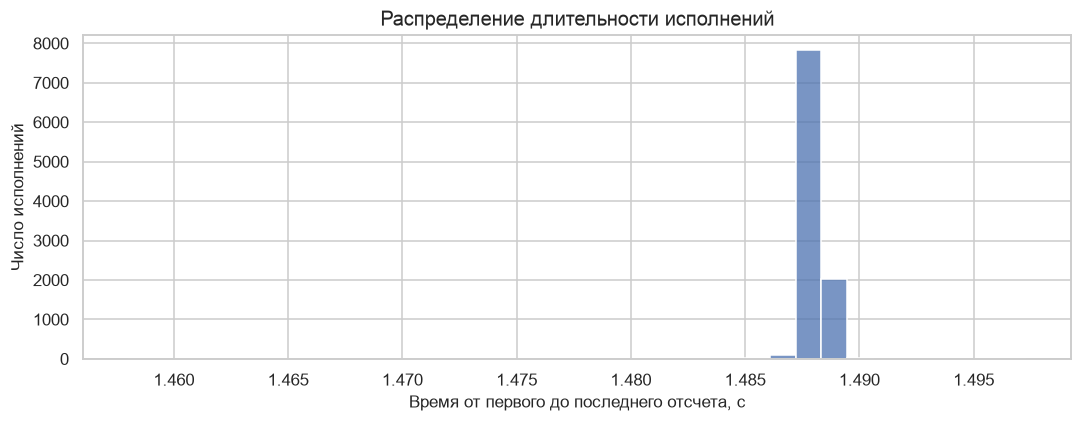

,count,mean,std,min,25%,50%,75%,max
n_samples,10000.0,150.00000,0.00000,150.00000,150.00000,150.00000,150.00000,150.00000
duration_s,10000.0,1.48816,0.00055,1.45800,1.48800,1.48813,1.48828,1.49731
median_dt_s,10000.0,0.00999,0.00001,0.00978,0.00999,0.00999,0.01000,0.01006
max_dt_s,10000.0,0.01255,0.00474,0.01027,0.01081,0.01089,0.01102,0.03067
gap_after_s,9000.0,1.91037,3.11228,0.06989,0.52948,1.07883,1.96749,76.58635


In [9]:
plt.figure(figsize=(10, 4))
sns.histplot(data=trials, x="duration_s", bins=35, color=plot_color)
plt.title("Распределение длительности исполнений")
plt.xlabel("Время от первого до последнего отсчета, с")
plt.ylabel("Число исполнений")
plt.tight_layout()
plt.show()

trials[["n_samples", "duration_s", "median_dt_s", "max_dt_s", "gap_after_s"]].describe().T.round(5)

**Вывод** Все 10 000 исполнений жестов содержат по 150 временных отсчетов. Средняя длительность записи от первого до последнего отсчета составляет 1,488 секунды при стандартном отклонении 0,00055 секунды.

Медианный интервал между соседними измерениями составляет около 0,00999 секунды, что соответствует частоте дискретизации примерно 100 Гц. Таким образом, временные характеристики данных согласуются с заявленной частотой регистрации. При этом максимальные интервалы между соседними измерениями в отдельных исполнениях достигают 0,03067 секунды. Возможно здесь требуется дополнительная проверка

Паузы между повторениями существенно различаются. Их медиана составляет 1,079 секунды, а максимальное значение достигает 76,586 секунды. Так как эти интервалы не относятся к выполнению жестов, их нужно будет скорее исключить из анализа временных характеристик.

## 3. Качество данных

### 3.1. Пропущенные значения и бесконечности

In [10]:
missing = signals.isna().sum()
missing_table = pd.DataFrame({
    "Столбец": missing.index,
    "Пропусков": missing.values,
    "Доля, %": (100 * missing.values / len(signals)).round(4),
})
missing_table

,Столбец,Пропусков,"Доля, %"
0,timestamp,0,0.0
1,user_id,0,0.0
2,flex_1,0,0.0
3,flex_2,0,0.0
4,flex_3,0,0.0
5,flex_4,0,0.0
6,flex_5,0,0.0
7,Qw,0,0.0
8,Qx,0,0.0
9,Qy,0,0.0


**Вывод.** Во всех 1 500 000 строках нет пропущенных и бесконечных сенсорных значений

### 3.2. Дубликаты и ошибки

In [11]:
quality_overview = pd.DataFrame({
    "Проверка": [
        "Файлы с пропусками", "Файлы с повторными строками", "Файлы с неположительным шагом времени",
        "Файлы с постоянным сенсорным каналом"
    ],
    "Количество файлов": [
        (file_stats.missing_cells > 0).sum(), (file_stats.duplicate_rows > 0).sum(),
        (file_stats.nonpositive_dt > 0).sum(), (file_stats.constant_channels > 0).sum()
    ]
})
quality_overview

,Проверка,Количество файлов
0,Файлы с пропусками,0
1,Файлы с повторными строками,0
2,Файлы с неположительным шагом времени,0
3,Файлы с постоянным сенсорным каналом,0


**Вывод.** Повторных строк, нарушений порядка временных меток и постоянных сенсорных каналов не найдено

### 3.3. Частота измерений и временные разрывы

Сравним интервалы внутри повторений с паузами между ними. Это позволяет проверить корректность разбиения по 150 строк и найти случаи, когда порог 0,2 с не отделяет соседние исполнения.

In [12]:
gaps = trials["gap_after_s"].dropna()
print("Медиана шага внутри повторения, с:", round(float(np.median(within_dt)), 6))
print("Максимальный шаг внутри повторения, с:", round(float(np.max(within_dt)), 6))
print("Минимальная пауза между повторениями, с:", round(float(gaps.min()), 6))
print("Паузы между повторениями короче 0,2 с:", int((gaps < 0.2).sum()))
print("Повторений с шагом внутри окна больше 0,02 с:", int((trials.large_dt_count > 0).sum()))
display(trials.loc[trials.gap_after_s < 0.2,
                   ["source_file", "trial_id", "gap_after_s"]].sort_values("gap_after_s").head(12))

Медиана шага внутри повторения, с: 0.009995
Максимальный шаг внутри повторения, с: 0.030674
Минимальная пауза между повторениями, с: 0.069892
Паузы между повторениями короче 0,2 с: 3
Повторений с шагом внутри окна больше 0,02 с: 970


,source_file,trial_id,gap_after_s
8808,ASL-Sensor-Dataglove-Dataset/023/a.csv,9,0.069892
2758,ASL-Sensor-Dataglove-Dataset/007/x.csv,9,0.069915
5507,ASL-Sensor-Dataglove-Dataset/014/t.csv,8,0.179221


**Вывод.** Медианный интервал между измерениями внутри повторений составляет 0,009995 с, максимальный достигает 0,030674 с. В 970 исполнениях обнаружен хотя бы один интервал продолжительностью более 0,02 с. Это может указывать на локальную нестабильность времени регистрации, однако не позволяет однозначно установить потерю измерений. Паузы между повторениями имеют различную продолжительность. 

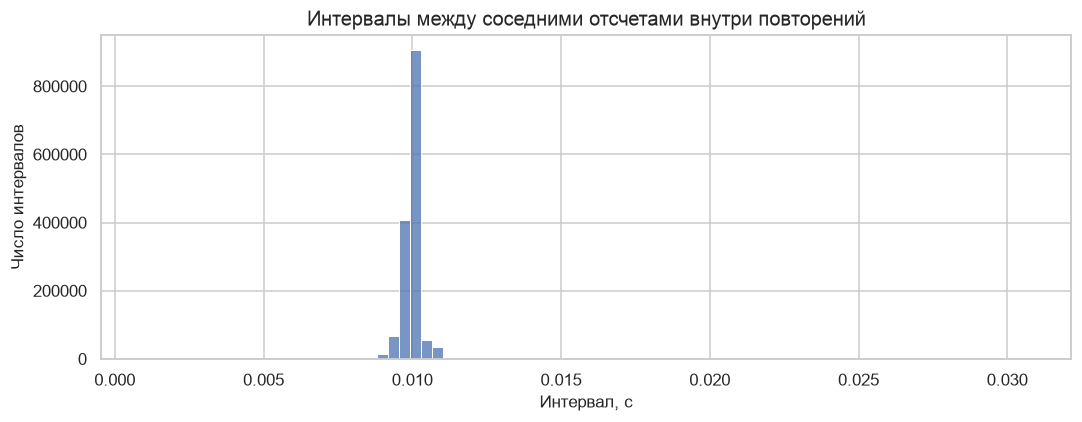

In [13]:
plt.figure(figsize=(10, 4))
sns.histplot(within_dt, bins=80, color=plot_color)
plt.title("Интервалы между соседними отсчетами внутри повторений")
plt.xlabel("Интервал, с")
plt.ylabel("Число интервалов")
plt.tight_layout()
plt.show()

### 3.4. Диапазоны и подозрительные значения

Посмотрим на диапазоны значений признака для каждого датчика изгиба

,min,median,max,negative_percent
flex_1,-520.0,4.0,836.0,46.61
flex_2,-180.0,-4.0,122.0,54.60
flex_3,-198.0,22.0,188.0,41.03
flex_4,-199.0,36.0,203.0,29.76
flex_5,-263.0,24.0,209.0,32.24


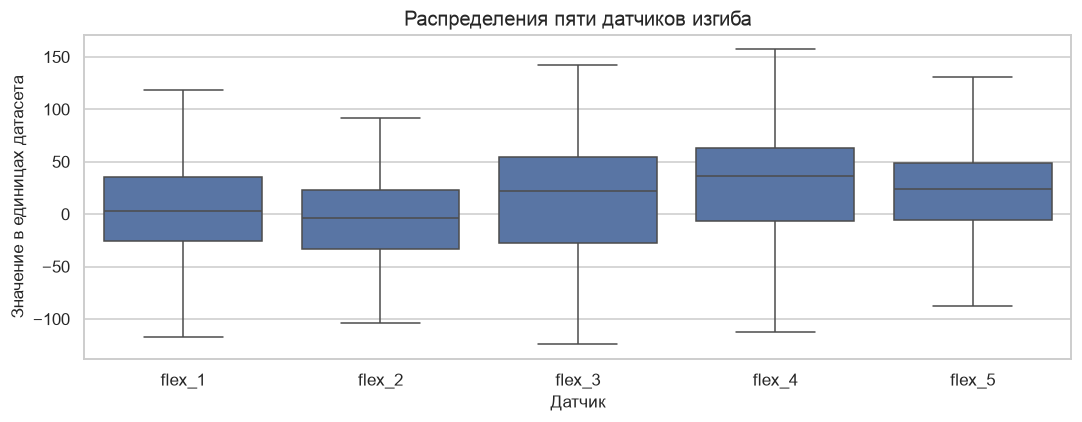

In [14]:
flex_ranges = signals[flex_cols].agg(["min", "median", "max"]).T
flex_ranges["negative_percent"] = (signals[flex_cols] < 0).mean().mul(100)
display(flex_ranges.round(2))

flex_plot = signals[flex_cols].iloc[::40].melt(var_name="Канал", value_name="Значение")
plt.figure(figsize=(10, 4))
sns.boxplot(data=flex_plot, x="Канал", y="Значение", color=plot_color, showfliers=False)
plt.title("Распределения пяти датчиков изгиба")
plt.xlabel("Датчик")
plt.ylabel("Значение в единицах датасета")
plt.tight_layout()
plt.show()

**Вывод.** Диапазоны значений с датчиков изгиба существенно различаются. Отрицательные значения встречаются во всех пяти каналах. Но без документации по калибровке и диапазонам датчиков от авторов датасета никакие из значений нельзя автоматически объявить ошибочными, нужно будет исследовать эту информацию

### 3.5. Кватернионы

Кватернион нужен для представления ориентации объекта в трехмерном пространстве

Для корректного кватерниона ориентации норма должна быть близка к единице. Рассчитаем абсолютное отклонение нормы от 1

Медиана отклонения от единицы: 1.77e-05
99-й процентиль отклонения: 6.96e-05
Отсчетов с отклонением более 0,02: 1


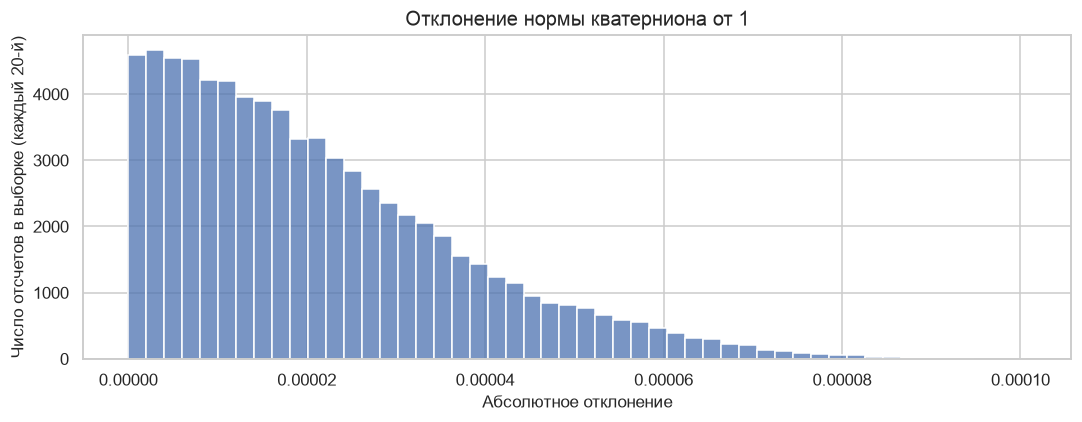

In [15]:
quaternion_norm = np.linalg.norm(signals[quat_cols].to_numpy(), axis=1)
norm_error = np.abs(quaternion_norm - 1)
print("Медиана отклонения от единицы:", round(float(np.median(norm_error)), 7))
print("99-й процентиль отклонения:", round(float(np.quantile(norm_error, 0.99)), 7))
print("Отсчетов с отклонением более 0,02:", int((norm_error > 0.02).sum()))

plt.figure(figsize=(10, 4))
sns.histplot(norm_error[::20], bins=50, color=plot_color)
plt.title("Отклонение нормы кватерниона от 1")
plt.xlabel("Абсолютное отклонение")
plt.ylabel("Число отсчетов в выборке (каждый 20-й)")
plt.tight_layout()
plt.show()

In [16]:
bad_quaternion_indices = np.flatnonzero(norm_error > 0.02)

bad_quaternion_rows = pd.DataFrame({
    "source_file": [csv_paths[i // 1500] for i in bad_quaternion_indices],
    "row_in_file": (bad_quaternion_indices % 1500).astype(int),
    "quaternion_norm": quaternion_norm[bad_quaternion_indices],
})
display(bad_quaternion_rows)

,source_file,row_in_file,quaternion_norm
0,ASL-Sensor-Dataglove-Dataset/012/p.csv,590,0.239346


**Вывод.** Нормы кватернионов практически во всех измерениях близки к 1. Исключение составляет строка с индексом 590 в файле 012/p.csv, где норма равна 0,2393. В этой строке, кажется, съехали значения6 так как flex_5 = 0.970886, хотя в соседних строках значения этого канала находится около 60. Значение 0.970886 совпадает с типичным значением Qw, которое стоит в соседней колонке. Нужно проверить, мб ошибка! ‼️

### 3.6. Выбросы в значениях датчиков изгиба

В качестве простой диагностики отметим отсчеты, отличающиеся от локальной медианы пяти соседних значений более чем на 15 единиц. Порог скорее диагностический, выбран для поиска кандидатов на выбросы, а не как критерий ошибки

,Канал,Подозрительных отсчетов,"Доля, %"
0,flex_1,8458,0.564
1,flex_2,6928,0.462
2,flex_3,10199,0.680
3,flex_4,20675,1.378
4,flex_5,19681,1.312


Исполнений хотя бы с одним подозрительным отсчетом: 9924


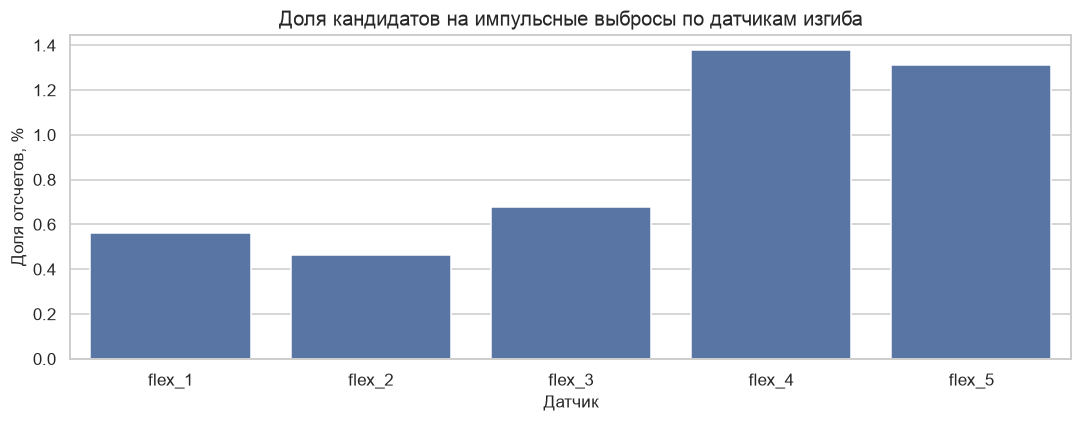

In [17]:
spike_summary = pd.DataFrame({
    "Канал": flex_cols,
    "Подозрительных отсчетов": spikes_by_channel.values,
    "Доля, %": (100 * spikes_by_channel.values / len(signals)).round(3),
})
display(spike_summary)
print("Исполнений хотя бы с одним подозрительным отсчетом:", int((trials.spike_count > 0).sum()))

plt.figure(figsize=(10, 4))
sns.barplot(data=spike_summary, x="Канал", y="Доля, %", color=plot_color)
plt.title("Доля кандидатов на импульсные выбросы по датчикам изгиба")
plt.xlabel("Датчик")
plt.ylabel("Доля отсчетов, %")
plt.tight_layout()
plt.show()

**Вывод.** По выбранному диагностическому порогу доля подозрительных отсчетов составляет от 0,462% для `flex_2` до 1,378% для `flex_4`.

### 3.7. Пример сигнала

Посмотрим на первое повторение `001/a.csv`. Хочется посмотреть как меняются показания для каждого сенсора во время одного исполнения.  

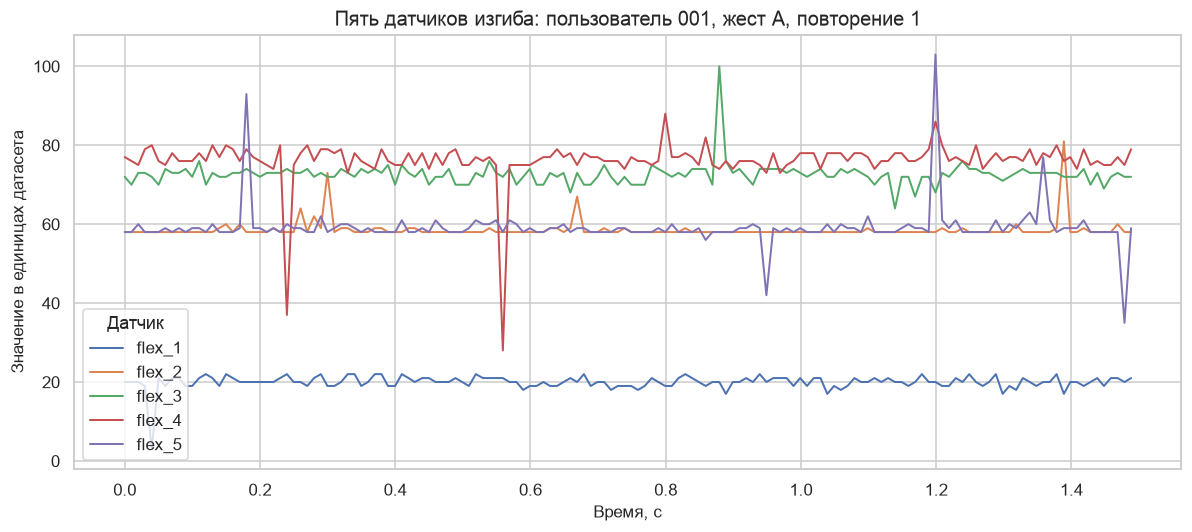

In [18]:
with ZipFile(archive_path) as archive:
    with archive.open("ASL-Sensor-Dataglove-Dataset/001/a.csv") as file:
        a_file = pd.read_csv(file)

first_trial = a_file.iloc[:150].copy()
first_trial["time_s"] = first_trial.timestamp - first_trial.timestamp.iloc[0]
# широкий -> длинный формат
plot_data = first_trial.melt(id_vars="time_s", value_vars=flex_cols,var_name="Датчик", value_name="Значение")
plt.figure(figsize=(11, 5))
sns.lineplot(data=plot_data, x="time_s", y="Значение", hue="Датчик", linewidth=1.3)
plt.title("Пять датчиков изгиба: пользователь 001, жест A, повторение 1")
plt.xlabel("Время, с")
plt.ylabel("Значение в единицах датасета")
plt.tight_layout()
plt.show()

**Вывод**: На графике жеста A видно, что показания пяти сенсоров  сохраняются на стабильных уровнях с небольшими колебаниями. Это согласуется с характером статического жеста, при котором конфигурация пальцев практически не изменяется. При этом в отдельных сенсорах наблюдаются резкие кратковременные отклонения от основного уровня сигнала. Особенно выраженные скачки присутствуют у flex_4 и flex_5. Поскольку значения быстро возвращаются к исходному уровню, такие отклонения могут быть связаны с импульсным шумом или артефактами измерения

## Промежуточный Вывод

В этой части мы изучили структуру датасета и убедились, что он соответствует заявленным характеристикам: количеству пользователей, классов и повторений. Пропущенных значений и дубликатов не обнаружено. Медианный интервал между измерениями внутри повторений составляет около 0,01 с – это соответствует заявленной частоте сбора данных в 100 Гц.

При проверке качества данных обнаружена аномалия в одной строке файла `012/p.csv`: значения некоторых признаков, вероятно, смещены относительно своих столбцов. Этот случай требует дополнительной проверки.

Также выявлены резкие кратковременные скачки с датчиков изгиба. При выбранном пороге отклонения от локальной медианы более чем на 15 единиц их доля не превышает 1,5% для каждого сенсора. Такие скачки могут быть связаны с шумом измерений или особенностями выполнения жестов. В дальнейшем стоит исследовать их природу и обосновать выбор порога для обнаружения выбросов.

## 4. Временная структура: сравнение повторений одного и того же жеста

Сравним медианные показания датчиков изгиба в десяти исполнениях буквы `a` одним пользователем. Это позволяет оценить воспроизводимость одного жеста.

In [19]:
a_mask = (groups == "001") & (y == "a")
a_flex = X[a_mask][:, :, [sensor_cols.index(col) for col in flex_cols]]

a_medians = pd.DataFrame(
    np.median(a_flex, axis=1),
    index=np.arange(1, len(a_flex) + 1),
    columns=flex_cols,
)
a_medians.index.name = "Повторение"
print("Размах медиан между повторениями:")
display(a_medians.round(1))
display((a_medians.max() - a_medians.min()).round(1).rename("Размах"))

Размах медиан между повторениями:


,flex_1,flex_2,flex_3,flex_4,flex_5
Повторение,,,,,
1,20.0,58.0,73.0,76.0,58.5
2,20.0,58.0,73.0,76.0,59.0
3,18.0,57.0,67.0,72.0,56.0
4,19.0,57.0,68.0,72.0,57.0
5,19.0,57.0,68.0,72.5,57.5
6,20.0,58.0,70.0,73.0,58.0
7,24.0,58.0,76.0,76.0,58.0
8,25.0,59.0,77.0,78.0,58.0
9,25.0,59.0,77.0,77.0,58.0


flex_1     7.0
flex_2     2.0
flex_3    10.0
flex_4     6.0
flex_5     3.0
Name: Размах, dtype: float32

**Вывод.** У одного пользователя медианы значений с датчиков изгиба между десятью исполнениями буквы A изменяются неодинаково, так как размах составляет 2 единицы для `flex_2` и 10 для `flex_3`. 

## 5. Дополнение к анализу сенсоров

Сравним исходное ускорение с двумя вариантами ускорения после компенсации гравитации.

In [20]:
gyro_idx = [sensor_cols.index(col) for col in gyro_cols]
acc_idx = [sensor_cols.index(col) for col in acc_cols]
body_idx = [sensor_cols.index(col) for col in body_cols]
world_idx = [sensor_cols.index(col) for col in world_cols]
quat_idx = [sensor_cols.index(col) for col in quat_cols]

# получаем один показатель 
gyro_norm = np.linalg.norm(X[:, :, gyro_idx], axis=2)
acc_world_norm = np.linalg.norm(X[:, :, world_idx], axis=2)

acc_summary = pd.DataFrame({
    "Исходное ускорение": np.linalg.norm(X[:, :, acc_idx], axis=2).ravel(),
    "Без гравитации, body": np.linalg.norm(X[:, :, body_idx], axis=2).ravel(),
    "Без гравитации, world": acc_world_norm.ravel(),
}).agg(["median", lambda values: values.quantile(0.95)]).T
acc_summary.columns = ["Медиана", "95-й процентиль"]
display(acc_summary.round(3))

,Медиана,95-й процентиль
Исходное ускорение,9.674,13.123
"Без гравитации, body",0.356,6.786
"Без гравитации, world",0.355,6.785


**Вывод.** Медиана нормы исходного ускорения равна 9,674. После компенсации гравитации она снижается до 0,356 в системе координат перчатки и 0,355 в системе координат земли. Сходство двух последних показателей вполне ожидаемо и для дальнешей работы можно оставить один, чтобы не дублировать признаки. ‼️

### 5.1. Примеры движения для букв A и Z

Сравним первый показ `a` и `z` пользователя `001`. Буква A является статической, Z требует движения кисти

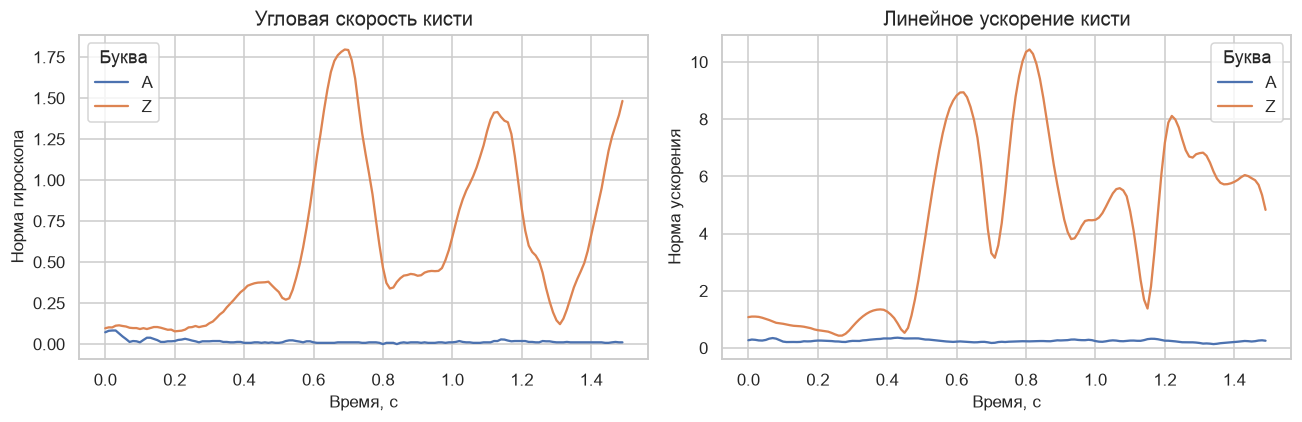

In [21]:
examples = []
for letter in ["a", "z"]:
    sample_index = np.flatnonzero((groups == "001") & (y == letter))[0]
    time_axis = np.arange(X.shape[1]) / 100  # частота 100 Гц == 100 измерений в сек
    examples.append(pd.DataFrame({
        "Время, с": time_axis,
        "Буква": letter.upper(),
        "Норма гироскопа": gyro_norm[sample_index],
        "Норма ускорения": acc_world_norm[sample_index],
    }))
example_motion = pd.concat(examples, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=example_motion, x="Время, с", y="Норма гироскопа", hue="Буква", ax=axes[0])
sns.lineplot(data=example_motion, x="Время, с", y="Норма ускорения", hue="Буква", ax=axes[1])
axes[0].set_title("Угловая скорость кисти")
axes[1].set_title("Линейное ускорение кисти")
plt.tight_layout()
plt.show()

**Вывод.** Для буквы Z видны выраженные пики угловой скорости и ускорения. У буквы A обе нормы остаются намного ниже и можно сказать, что они довольно статичны

## 6. Признаки на уровне исполнения жеста

Извлечем уровень и разброс значений датчиков изгиба, изменение значений датчиков изгиба во времени, интенсивность движения и изменение ориентации кисти. Мы попробовали посмотреть на различные признаки на основе тех, что уже есть а датасете. Ниже их описание:

| Признак | Значение | Для чего может быть полезен |
|---|---|---|
| `median` (5) | Медианное значение каждого датчика изгиба пальцев | Определение конфигурации пальцев |
| `iqr` (5) | Разброс центральных 50% показаний датчика | Оценка изменения положения пальцев во время жеста |
| `change` (5) | Медианное абсолютное изменение показаний между соседними отсчетами | Оценка локальной изменчивости сигнала |
| `gyro_rms` | Среднеквадратическая угловая скорость | Оценка интенсивности вращения кисти |
| `gyro_p95` | 95-й процентиль угловой скорости | Выявление участков с быстрым вращением |
| `acc_rms` | Среднеквадратическое линейное ускорение | Оценка интенсивности движения кисти |
| `acc_p95` | 95-й процентиль линейного ускорения | Выявление участков с резким ускорением |
| `rotation_deg` | Угол между начальной и конечной ориентациями кисти | Оценка итогового поворота кисти |
| `rotation_step_p95_deg` | 95-й процентиль углов между соседними ориентациями | Оценка резких изменений ориентации кисти |


In [22]:
features = trials[["sample_id", "subject_id", "gesture", "trial_id"]].copy()

for col in flex_cols:
    values = X[:, :, sensor_cols.index(col)]
    features[f"{col}_median"] = np.median(values, axis=1)
    # межкварт размах
    features[f"{col}_iqr"] = np.percentile(values, 75, axis=1) - np.percentile(values, 25, axis=1)
    features[f"{col}_change"] = np.median(np.abs(np.diff(values, axis=1)), axis=1)

features["gyro_rms"] = np.sqrt(np.mean(gyro_norm ** 2, axis=1))
features["gyro_p95"] = np.percentile(gyro_norm, 95, axis=1)
features["acc_rms"] = np.sqrt(np.mean(acc_world_norm ** 2, axis=1))
features["acc_p95"] = np.percentile(acc_world_norm, 95, axis=1)

# нормализуем кватернионы для вычисления углов
q = X[:, :, quat_idx].astype(np.float64)
q /= np.maximum(np.linalg.norm(q, axis=2, keepdims=True), 1e-12)

end_dot = np.abs(np.sum(q[:, 0] * q[:, -1], axis=1)).clip(0, 1)
step_dot = np.abs(np.sum(q[:, :-1] * q[:, 1:], axis=2)).clip(0, 1)
features["rotation_deg"] = np.degrees(2 * np.arccos(end_dot))
features["rotation_step_p95_deg"] = np.percentile(np.degrees(2 * np.arccos(step_dot)), 95, axis=1)

feature_cols = features.columns.difference(["sample_id", "subject_id", "gesture", "trial_id"]).tolist()
features.head(5).round(3)

,sample_id,subject_id,gesture,trial_id,flex_1_median,flex_1_iqr,flex_1_change,flex_2_median,flex_2_iqr,flex_2_change,...,flex_4_change,flex_5_median,flex_5_iqr,flex_5_change,gyro_rms,gyro_p95,acc_rms,acc_p95,rotation_deg,rotation_step_p95_deg
0,001_a_01,001,a,1,20.0,2.0,1.0,58.0,0.00,0.0,...,2.0,58.5,1.0,1.0,0.021,0.036,0.252,0.334,0.956,0.055
1,001_a_02,001,a,2,20.0,2.0,1.0,58.0,0.00,0.0,...,2.0,59.0,1.0,1.0,0.029,0.072,0.247,0.388,3.601,0.135
2,001_a_03,001,a,3,18.0,2.0,1.0,57.0,1.75,1.0,...,1.0,56.0,2.0,2.0,0.017,0.029,0.200,0.337,0.920,0.050
3,001_a_04,001,a,4,19.0,2.0,1.0,57.0,1.00,1.0,...,1.0,57.0,2.0,1.0,0.013,0.024,0.163,0.232,0.249,0.036
4,001_a_05,001,a,5,19.0,2.0,1.0,57.0,1.75,1.0,...,1.0,57.5,1.0,1.0,0.027,0.055,0.204,0.322,3.127,0.093


Дальше работаем с этой таблице и с этими признаками

### 6.1. Показатели датчиков по разным буквам

Сравним медианные уровни сенсоров для нескольких более похожих и менее похожих букв.

In [23]:
flex_median_cols = [f"{col}_median" for col in flex_cols]
letter_profiles = features.groupby("gesture")[flex_median_cols].median()
# похожие конфигурации пальцев
similar_letters = ["u", "v", "c", "o", "g", "q",
                   "k", "p", "i", "j", "d", "z"]
print("Похожие буквы:")
display(letter_profiles.loc[similar_letters].round(1))

# Сильно различающиеся конфигурации пальцев
different_letters = ["a", "b", "s", "w"]
print("Различающиеся буквы:")
letter_profiles.loc[different_letters].round(1)

Похожие буквы:


,flex_1_median,flex_2_median,flex_3_median,flex_4_median,flex_5_median
gesture,,,,,
u,21.000000,-21.5,-46.0,56.0,42.0
v,19.000000,-28.5,-38.5,57.0,37.5
c,11.000000,25.0,30.0,28.0,21.0
o,41.000000,23.0,31.0,31.5,19.0
g,-19.500000,-10.0,58.0,57.5,43.0
q,-17.000000,-8.0,48.0,55.5,40.0
k,1.500000,-27.0,-13.5,46.0,29.0
p,-4.000000,-27.0,-8.5,46.0,28.0
i,44.000000,42.0,50.0,46.0,-36.0


Различающиеся буквы:


,flex_1_median,flex_2_median,flex_3_median,flex_4_median,flex_5_median
gesture,,,,,
a,-5.0,41.0,52.0,55.5,43.5
b,39.0,-14.0,-36.5,-48.5,-36.5
s,29.0,42.0,57.0,54.0,49.0
w,17.5,-17.0,-34.5,-46.5,54.5


In [24]:
motion_cols = [
    "gyro_rms",
    "acc_rms",
    "rotation_deg",
    "rotation_step_p95_deg"
]
motion_profiles = features.groupby("gesture")[motion_cols].median()
display(motion_profiles.loc[["i", "j", "d", "z"]].round(3))

,gyro_rms,acc_rms,rotation_deg,rotation_step_p95_deg
gesture,,,,
i,0.023,0.345,1.053,0.068
j,1.128,3.277,163.120,4.019
d,0.017,0.203,0.797,0.046
z,0.613,4.781,42.866,2.112


**Вывод.** похожие буквы имеют близкие медианные показания датчиков изгиба (K/P, G/Q и U/V). Для букв, различающихся направлением кисти или движением, необходимо дополнительно использовать данные IMU. Например, если смотреть по значениям датчика изгиба, то для I/J значения очень похожие, однако, если сравнивать медианные показатели ускорения и угловой скорости – то различия будут заметны.


## 7. Корреляции и связь признаков с классом

Корреляции рассчитаем по таблице исполнений, а не по отдельным отсчетам. Берем Спирмена, так как он измеряет силу не линейной зависимости, а монотонной, что важно для нас, так как распределения признаков могут быть несимметричны, в данных бывают выбросы, зависимости между признаками не всегда линейные.

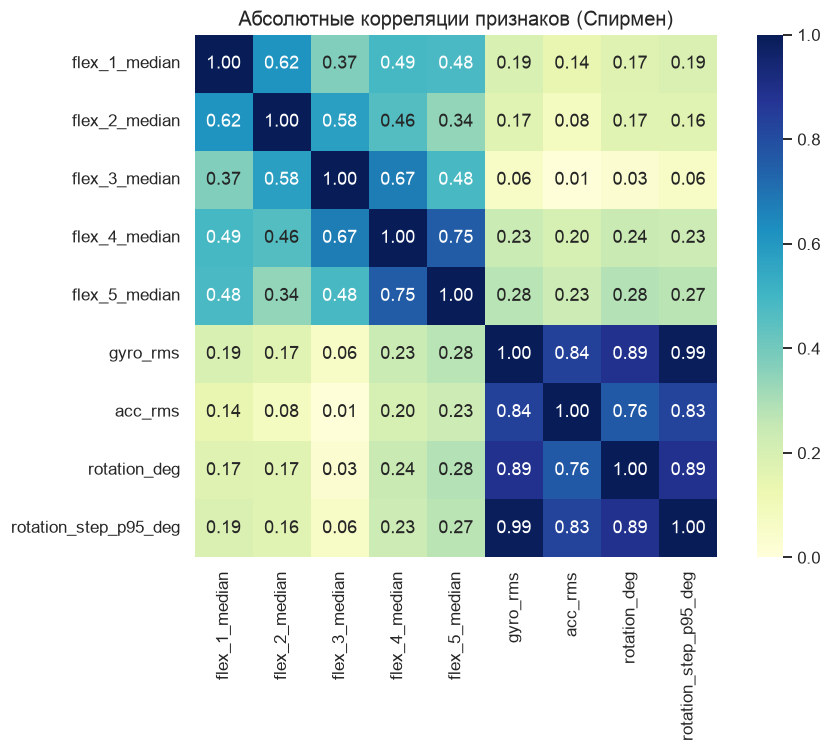

In [25]:
corr_cols = flex_median_cols + [
    "gyro_rms", "acc_rms", "rotation_deg", "rotation_step_p95_deg"
]
corr = features[corr_cols].corr(method="spearman").abs()
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True
)
plt.title("Абсолютные корреляции признаков (Спирмен)")
plt.tight_layout()
plt.show()

**Вывод.** Признаки движения из IMU сильно коррелируют друг с другой. Например, связь `gyro_rms` и `rotation_step_p95_deg` по Спирмену составляет 0,99. Среди значений датчиков изгиба наиболее выражена связь  между `flex_4_median` и `flex_5_median` (0,75).

### 7.1. Связь признаков с жестом и пользователем

Для нас важно понять, насколько значения каждого признака отличаются внутри жеста и между носителями. Так как мы хотим найти такие признаки, которые будут выделять жест среди других, но при этому не так сильно зависеть от индивидуальной подачи носителя.

Метка жеста является категориальной, поэтому  корреляция Пирсона с номером класса не подходит. Вместо нее вычислим долю разброса каждого признака, связанную с группировкой по жесту и по пользователю, через показатель η².

In [26]:
values = features[feature_cols]
means = values.mean() 
total_ss = ((values - means) ** 2).sum()

gesture_mean = values.groupby(features["gesture"]).transform("mean")
subject_mean = values.groupby(features["subject_id"]).transform("mean")

association = pd.DataFrame({
    "Признак": feature_cols,
    "η² жест": (((gesture_mean - means) ** 2).sum() / total_ss).values,
    "η² пользователь": (((subject_mean - means) ** 2).sum() / total_ss).values,
})
association = association.sort_values("η² жест", ascending=False)
display(association.round(3))

,Признак,η² жест,η² пользователь
18,gyro_rms,0.915,0.011
19,rotation_deg,0.899,0.009
17,gyro_p95,0.898,0.012
20,rotation_step_p95_deg,0.897,0.011
1,acc_rms,0.878,0.015
0,acc_p95,0.846,0.019
10,flex_3_median,0.805,0.147
6,flex_2_iqr,0.751,0.019
12,flex_4_iqr,0.677,0.040
13,flex_4_median,0.670,0.271


**Вывод.** Наибольшая связь с классом жеста обнаружена у динамических признаков `gyro_rms`, `rotation_deg` и `flex_3_median`, это значит, что каждый жест хорошо отличается от остальных по этим признакам.

### 7.2. Попарные распределения для похожих букв

Рассмотрим C, O, U и V в пространстве трех датчиков изгиба. Взяли рандомные 3, полный pairplot по 40 классам был бы перегружен.

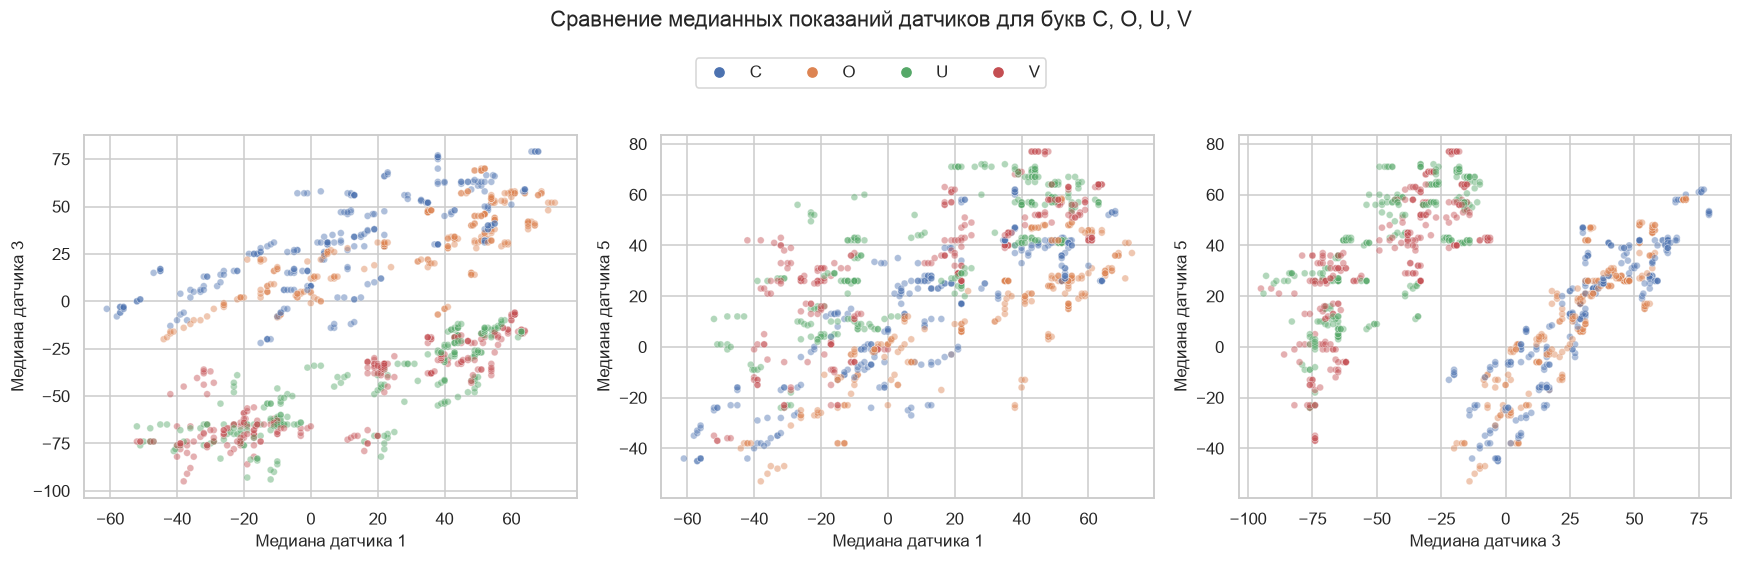

In [27]:
pair_data = features.loc[
    features["gesture"].isin(["c", "o", "u", "v"]),
    ["gesture", "flex_1_median", "flex_3_median", "flex_5_median"],
]
pairs = [
    ("flex_1_median", "flex_3_median"),
    ("flex_1_median", "flex_5_median"),
    ("flex_3_median", "flex_5_median")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(
        data=pair_data,
        x=x,
        y=y,
        hue="gesture",
        hue_order=["c", "o", "u", "v"],
        s=20,
        alpha=0.45,
        ax=ax,
        legend=False
    )

    ax.set_xlabel(f"Медиана датчика {x.split('_')[1]}")
    ax.set_ylabel(f"Медиана датчика {y.split('_')[1]}")

# легенда для всх графиков
handles, labels = axes[0].get_legend_handles_labels()

from matplotlib.lines import Line2D

colors = sns.color_palette(n_colors=4)
legend_handles = [
    Line2D([0], [0], marker="o", linestyle="", color=color, label=letter)
    for color, letter in zip(colors, ["C", "O", "U", "V"])
]

fig.legend(handles=legend_handles, loc="upper center",
           ncol=4, bbox_to_anchor=(0.5, 1.05))

fig.suptitle("Сравнение медианных показаний датчиков для букв C, O, U, V", y=1.13)
plt.tight_layout()
plt.show()

**Вывод.** Медианные показания датчиков позволяют частично разделить буквы C/O и U/V. Наиболее заметные различия между этими группами наблюдаются когда присутствует третий датчик. При этом распределения внутри пар C/O и U/V существенно перекрываются независимо от выбранной пары признаков. Это хороший пример того, что отдельные медианные показания могут плохр различать буквы со схожей конфигурацией пальцев.

## 8. Базовые модели распознавания букв ASL

Здесь хотим получить воспроизводимые ML- и DL-бейзлайны, классифицируя 26 букв, слова не берем пока. 

Объект классификации - одно исполнение длительностью 150 отсчетов. 

### 8.1. Данные, разбиение по пользователям и проверки

Сравним три группы агрегированных признаков: 5 медиан, 15 характеристик датчиков изгиба и все 21 признак. Разбиение зафиксируем один раз и используем для всех моделей.

In [28]:
feature_cols

['acc_p95',
 'acc_rms',
 'flex_1_change',
 'flex_1_iqr',
 'flex_1_median',
 'flex_2_change',
 'flex_2_iqr',
 'flex_2_median',
 'flex_3_change',
 'flex_3_iqr',
 'flex_3_median',
 'flex_4_change',
 'flex_4_iqr',
 'flex_4_median',
 'flex_5_change',
 'flex_5_iqr',
 'flex_5_median',
 'gyro_p95',
 'gyro_rms',
 'rotation_deg',
 'rotation_step_p95_deg']

In [29]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

letter_mask = features["gesture"].str.fullmatch(r"[a-z]").to_numpy()
letter_features = features.loc[letter_mask].reset_index(drop=True)
X_letters = X[letter_mask]

encoder = LabelEncoder()
y_letters = encoder.fit_transform(letter_features["gesture"])
subject_letters = letter_features["subject_id"].to_numpy()

# 5 пользователей для теста, 4 для валидации – не членим пользователей между выборками
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_val_idx, test_idx = next(outer.split(letter_features, y_letters, groups=subject_letters))
inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
sub_train, sub_val = next(inner.split(
    letter_features.iloc[train_val_idx], y_letters[train_val_idx],
    groups=subject_letters[train_val_idx]
))
train_idx, val_idx = train_val_idx[sub_train], train_val_idx[sub_val]

train_users = set(subject_letters[train_idx])
val_users = set(subject_letters[val_idx])
test_users = set(subject_letters[test_idx])

# проверяем, что нет утечек по пользователям
assert not (train_users & val_users or train_users & test_users or val_users & test_users)
assert len(encoder.classes_) == 26
assert len(letter_features) == 6500
assert all(set(y_letters[idx]) == set(range(26)) for idx in (train_idx, val_idx, test_idx))

flex_15_cols = [col for col in feature_cols if col.startswith("flex_")]
feature_sets = {
    "5 медиан": flex_median_cols,
    "15 признаков изгиба": flex_15_cols,
    "21 признак": feature_cols,
}

split_info = pd.DataFrame([
    {"Выборка": name, "Исполнений": len(idx), "Пользователей": len(users),
     "ID пользователей": ", ".join(sorted(users))}
    for name, idx, users in [
        ("Обучение", train_idx, train_users),
        ("Валидация", val_idx, val_users),
        ("Тест", test_idx, test_users),
    ]
])
display(split_info)
print("Классов:", len(encoder.classes_), "Наборы признаков:",
      {name: len(cols) for name, cols in feature_sets.items()})

,Выборка,Исполнений,Пользователей,ID пользователей
0,Обучение,4160,16,"004, 005, 006, 007, 008, 010, 011, 013, 014, 0..."
1,Валидация,1040,4,"002, 003, 020, 022"
2,Тест,1300,5,"001, 009, 012, 017, 024"


Классов: 26 Наборы признаков: {'5 медиан': 5, '15 признаков изгиба': 15, '21 признак': 21}


### 8.2. ML: логистическая регрессия и случайный лес

Dummy – бейзлайн, который показывает самый частотный класс.

In [30]:
def score_predictions(y_true, predicted):
    res = {
        "Accuracy": accuracy_score(y_true, predicted),
        "Macro F1": f1_score(y_true, predicted, average="macro", zero_division=0),}
    return res

ml_models = {}
ml_rows = []

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(letter_features.iloc[train_idx][flex_median_cols], y_letters[train_idx])
for split_name, idx in [("Валидация", val_idx), ("Тест", test_idx)]:
    pred = dummy.predict(letter_features.iloc[idx][flex_median_cols])
    ml_rows.append({"Модель": "Dummy", "Признаки": "5 медиан", "Выборка": split_name, **score_predictions(y_letters[idx], pred)})

for feature_set_name, columns in feature_sets.items():
    train_table = letter_features.iloc[train_idx][columns]
    for model_name, model in [
        ("LogisticRegression", make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1500, C=1.0) # берем пока дефолтные значения, их конечно можно подбирать
        )),
        ("RandomForest", RandomForestClassifier(
            n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=42
        )),
    ]:
        key = (model_name, feature_set_name)
        model.fit(train_table, y_letters[train_idx])
        ml_models[key] = model
        for split_name, idx in [("Валидация", val_idx), ("Тест", test_idx)]:
            pred = model.predict(letter_features.iloc[idx][columns])
            ml_rows.append({"Модель": model_name, "Признаки": feature_set_name,
                            "Выборка": split_name,
                            **score_predictions(y_letters[idx], pred)})

ml_results = pd.DataFrame(ml_rows)
display(ml_results.pivot_table(index=["Модель", "Признаки"], columns="Выборка", values=["Accuracy", "Macro F1"]).round(3))

# Лучший ML-вариант выбирается только по валидации.
val_ml = ml_results[(ml_results["Выборка"] == "Валидация") &
                    (ml_results["Модель"] != "Dummy")]
best_ml_row = val_ml.sort_values("Macro F1", ascending=False).iloc[0]
best_ml_key = (best_ml_row["Модель"], best_ml_row["Признаки"])
print("Лучший ML по валидации:", best_ml_key)

Accuracy         Macro F1       
Выборка                                Валидация   Тест Валидация   Тест
Модель             Признаки                                             
Dummy              5 медиан                0.038  0.038     0.003  0.003
LogisticRegression 15 признаков изгиба     0.547  0.596     0.543  0.587
                   21 признак              0.693  0.722     0.689  0.717
                   5 медиан                0.538  0.603     0.532  0.597
RandomForest       15 признаков изгиба     0.461  0.548     0.453  0.535
                   21 признак              0.612  0.675     0.603  0.669
                   5 медиан                0.452  0.557     0.432  0.537

Лучший ML по валидации: ('LogisticRegression', '21 признак')


**Ввывод** Логистическая регрессия с 21 признаком показала на тесте Accuracy **0,722** и Macro F1 **0,717**, с пятью медианами - **0,603** и **0,597**. Для случайного леса Accuracy увеличилась с **0,557** до **0,675**. Интересно, что качество моделей лучше на сете из 5 медиан, а не на 15 признаках, построенных на данных с flex-признаков – лишние признаки генерировать тоже не лучшая опция

### 8.3. DL: MLP на 21 агрегированном признаке

Небольшая полносвязная нейросеть служит DL-бейзлайном для табличных признаков.

In [31]:
import copy
import random
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cpu")  # Бейзлайны воспроизводимы без GPU.

# Масштабирование только по обучающим пользователям.
tab_scaler = StandardScaler().fit(letter_features.iloc[train_idx][feature_cols])
tab_data = np.clip(tab_scaler.transform(letter_features[feature_cols]), -8, 8).astype(np.float32) # надо более осознанно подобрать значения для клипа


def loader_from_numpy(inputs, indices, batch_size=128, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(inputs[indices]), # объединяем два датасета 
        torch.from_numpy(y_letters[indices].astype(np.int64)))
    # разбиваем на мини батчи
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)


def predict_torch(model, data_loader):
    # переключились на режим оценки
    model.eval()
    predictions = []
    with torch.no_grad(): # не вычисляем значения градиента
        for xb, _ in data_loader:
            predictions.append(model(xb.to(device)).argmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)


def fit_torch(model, inputs, max_epochs=20, patience=4, learning_rate=1e-3):
    train_loader = loader_from_numpy(inputs, train_idx, shuffle=True)
    val_loader = loader_from_numpy(inputs, val_idx)
    # оптимизатор выбрали рандомно, но так как он объединяет метод моментов и rmsprop – мб лучший вариант сейчас
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)
    criterion = nn.CrossEntropyLoss()
    history = []
    best_f1, best_state, best_epoch = -1, None, 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward() # вычисляем градиент
            optimizer.step() # делаем шаг 
            losses.append(float(loss.item())) # аппендим значение ошибки 

        val_pred = predict_torch(model, val_loader) # предсказываем на валидаци
        val_f1 = f1_score(y_letters[val_idx], val_pred, average="macro", zero_division=0)
        history.append({"Эпоха": epoch, "Train loss": np.mean(losses), "Val Macro F1": val_f1})
        if val_f1 > best_f1 + 1e-4:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        if epoch - best_epoch >= patience: # ранняя остановка
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


class GestureMLP(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        # взяли два скрытых слоя, накинули функцию активации и дропаут
        self.network = nn.Sequential(
            nn.Linear(n_features, 64), 
            nn.ReLU(), 
            nn.Dropout(0.2),
            nn.Linear(64, 32), 
            nn.ReLU(),
            nn.Linear(32, n_classes)
        )

    def forward(self, x):
        return self.network(x)


mlp = GestureMLP(len(feature_cols), len(encoder.classes_)).to(device)
mlp, mlp_history, mlp_epoch = fit_torch(mlp, tab_data, max_epochs=25, patience=5)
mlp_val_pred = predict_torch(mlp, loader_from_numpy(tab_data, val_idx))
mlp_test_pred = predict_torch(mlp, loader_from_numpy(tab_data, test_idx))
print("MLP: лучшая эпоха", mlp_epoch)
display(mlp_history.tail(8).round(3))
print("MLP, валидация:", score_predictions(y_letters[val_idx], mlp_val_pred))

MLP: лучшая эпоха 24


,Эпоха,Train loss,Val Macro F1
17,18,0.846,0.648
18,19,0.842,0.661
19,20,0.820,0.644
20,21,0.810,0.675
21,22,0.803,0.656
22,23,0.790,0.661
23,24,0.777,0.688
24,25,0.771,0.660


MLP, валидация: {'Accuracy': 0.6942307692307692, 'Macro F1': 0.6876729777198717}


### 8.4. DL: 1D-CNN на исходных временных рядах

Сверточная сеть получает все 150 временных отсчетов 21 сенсорного канала, то есть  доступен порядок изменения сигнала, который теряется при вычислении статистических признаков. Нормировка **каждого канала** производится по отсчетам обучающих пользователей.

In [32]:
seq_scaler = StandardScaler()
seq_scaler.fit(X_letters[train_idx].reshape(-1, X_letters.shape[-1]))
seq_data = np.clip(
    seq_scaler.transform(X_letters.reshape(-1, X_letters.shape[-1]))
    .reshape(X_letters.shape), -8, 8
).astype(np.float32)
# Conv1d принимает форму (исполнения, каналы, отсчеты).
seq_data = np.transpose(seq_data, (0, 2, 1)).copy()


class GestureCNN(nn.Module):
    def __init__(self, n_channels, n_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 96, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(),
            nn.Linear(96 * 8, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.network(x)


cnn = GestureCNN(seq_data.shape[1], len(encoder.classes_)).to(device)
cnn, cnn_history, cnn_epoch = fit_torch(cnn, seq_data, max_epochs=20, patience=5)
cnn_val_pred = predict_torch(cnn, loader_from_numpy(seq_data, val_idx))
cnn_test_pred = predict_torch(cnn, loader_from_numpy(seq_data, test_idx))
print("CNN: лучшая эпоха", cnn_epoch)
display(cnn_history.tail(8).round(3))
print("CNN, валидация:", score_predictions(y_letters[val_idx], cnn_val_pred))

CNN: лучшая эпоха 10


,Эпоха,Train loss,Val Macro F1
7,8,0.399,0.740
8,9,0.362,0.724
9,10,0.342,0.765
10,11,0.298,0.739
11,12,0.279,0.736
12,13,0.263,0.739
13,14,0.261,0.756
14,15,0.228,0.722


CNN, валидация: {'Accuracy': 0.7798076923076923, 'Macro F1': 0.7648915566689328}


### 8.5. Сравнение моделей и ошибки по буквам

Для ML приводим все заранее заданные эксперименты, для DL - результат после ранней остановки по валидации. Нельзя выбирать лучший вариант по тестовой метрике: для выбора служит валидация. Дополнительно посмотрим пары букв, которые модель чаще всего путает.

In [33]:
dl_rows = []
for name, val_pred, test_pred in [
    ("MLP", mlp_val_pred, mlp_test_pred),
    ("CNN-1D", cnn_val_pred, cnn_test_pred),
]:
    for split_name, idx, pred in [("Валидация", val_idx, val_pred),
                                   ("Тест", test_idx, test_pred)]:
        dl_rows.append({"Модель": name, "Признаки": "21 агрегированный" if name == "MLP" else "21 канал x 150",
                        "Выборка": split_name, **score_predictions(y_letters[idx], pred)})

all_results = pd.concat([ml_results, pd.DataFrame(dl_rows)], ignore_index=True)
comparison = all_results.pivot_table(
    index=["Модель", "Признаки"], columns="Выборка", values=["Accuracy", "Macro F1"]
)
display(comparison.round(3))

# Самый сильный ML-бейзлайн по валидации (не по тесту).
best_ml = ml_models[best_ml_key]
best_ml_cols = feature_sets[best_ml_key[1]]
best_ml_test_pred = best_ml.predict(letter_features.iloc[test_idx][best_ml_cols])


Accuracy         Macro F1       
Выборка                                Валидация   Тест Валидация   Тест
Модель             Признаки                                             
CNN-1D             21 канал x 150          0.780  0.742     0.765  0.739
Dummy              5 медиан                0.038  0.038     0.003  0.003
LogisticRegression 15 признаков изгиба     0.547  0.596     0.543  0.587
                   21 признак              0.693  0.722     0.689  0.717
                   5 медиан                0.538  0.603     0.532  0.597
MLP                21 агрегированный       0.694  0.698     0.688  0.687
RandomForest       15 признаков изгиба     0.461  0.548     0.453  0.535
                   21 признак              0.612  0.675     0.603  0.669
                   5 медиан                0.452  0.557     0.432  0.537

**Результат DL.** На тестовых пользователях CNN-1D достигла **Accuracy 0,735 / Macro F1 0,731**, MLP - **0,698 / 0,687**. CNN использует временной порядок исходных измерений, поэтому ее результат позволяет оценить потенциальную пользу последовательностей. Однако разница с логистической регрессией на 21 признаке (**0,722 / 0,717**) небольшая и на одном разбиении не позволяет утверждать, что CNN устойчиво лучше.

### 8.5.1. Устойчивость к смене пользователя

Проверим Accuracy отдельно для пяти тестовых пользователей. Общая точность может скрывать существенные различия между участниками.

In [34]:
best_ml = ml_models[best_ml_key]
best_ml_cols = feature_sets[best_ml_key[1]]
best_ml_test_pred = best_ml.predict(letter_features.iloc[test_idx][best_ml_cols])

per_user_rows = []
for name, pred in [("Лучший ML", best_ml_test_pred), ("CNN-1D", cnn_test_pred)]:
    for user in sorted(test_users):
        mask = subject_letters[test_idx] == user
        per_user_rows.append({
            "Модель": name, "Пользователь": user,
            "Accuracy": accuracy_score(y_letters[test_idx][mask], pred[mask]),
            "Macro F1": f1_score(y_letters[test_idx][mask], pred[mask], average="macro")
        })
per_user_results = pd.DataFrame(per_user_rows)
display(per_user_results.pivot(index="Пользователь", columns="Модель", values="Accuracy").round(3))

Модель,CNN-1D,Лучший ML
Пользователь,,
001,0.792,0.785
009,0.812,0.862
012,0.738,0.696
017,0.673,0.592
024,0.692,0.677


**Вывод по пользователям.** Мы делали разделение по пользователям, чтобы исключить попадание исполнений одного человека одновременно в обучение и тест. Это позволяет оценить обобщающую способность моделей на новых пользователях. Однако мы видим  заметный разброс точности между участниками, поэтому в будущем для более надежного сравнения моделей необходимо проводить оценку на нескольких групповых разбиениях, чтобы различные пользователеи побывали и в обучении, и в тесте.

### 8.6. Сложные пары букв

Посчитаем долю взаимных ошибок для похожих пар (C/O, U/V, I/J, D/Z, G/Q, K/P). Доля считается от числа **всех тестовых исполнений двух букв**, включая правильно распознанные. Ноль означает отсутствие ошибок именно между буквами этой пары, но не гарантирует хорошую точность для каждой буквы.

In [35]:

similar_pairs = [("c", "o"), ("u", "v"), ("i", "j"), # смотрели выше на них 
                 ("d", "z"), ("g", "q"), ("k", "p")]
pair_rows = []
for name, pred in [
    ("Лучший ML", best_ml_test_pred), ("MLP", mlp_test_pred), ("CNN-1D", cnn_test_pred)
]:
    # обратно индексы в буквы переводим
    true_letters = encoder.inverse_transform(y_letters[test_idx])
    pred_letters = encoder.inverse_transform(pred)
    for a, b in similar_pairs:
        n = np.isin(true_letters, [a, b]).sum()
        swapped = ((true_letters == a) & (pred_letters == b)) | ((true_letters == b) & (pred_letters == a))
        # если модель предсказала J вместо U, это ошибка классификации, не учитываем тут
        pair_rows.append({"Модель": name, "Пара": f"{a.upper()}/{b.upper()}",
                          "Взаимных ошибок": int(swapped.sum()),
                          "Доля, %": 100 * swapped.sum() / n})

pair_errors = pd.DataFrame(pair_rows)
display(pair_errors.pivot(index="Пара", columns="Модель", values="Доля, %").round(1))

Модель,CNN-1D,MLP,Лучший ML
Пара,,,
C/O,23.0,20.0,18.0
D/Z,0.0,0.0,0.0
G/Q,0.0,0.0,0.0
I/J,0.0,0.0,0.0
K/P,0.0,46.0,45.0
U/V,44.0,50.0,51.0


U/V является сложной парой, так как доля взаимной путаницы составляет **51%** у лучшей ML-модели и **46%** у CNN. Для K/P взаимная путаница снижается с **45%** у ML до **0%** у CNN. 

## 9. SHAP: интерпретация случайного леса

SHAP рассчитываем для случайного леса с 21 агрегированным признаком. Это позволяет интерпретировать именно полный набор разработанных признаков. Используем 104 тестовых исполнения и `TreeExplainer`; SHAP вычисляется для вероятностей 26 классов. Усреднение модулей по объектам и классам показывает глобальную важность признака для этой модели.


,Признак,Средний |SHAP|
10,flex_3_median,0.0249
7,flex_2_median,0.0165
16,flex_5_median,0.0145
13,flex_4_median,0.0120
4,flex_1_median,0.0118
1,acc_rms,0.0110
0,acc_p95,0.0068
17,gyro_p95,0.0032
18,gyro_rms,0.0031
20,rotation_step_p95_deg,0.0030


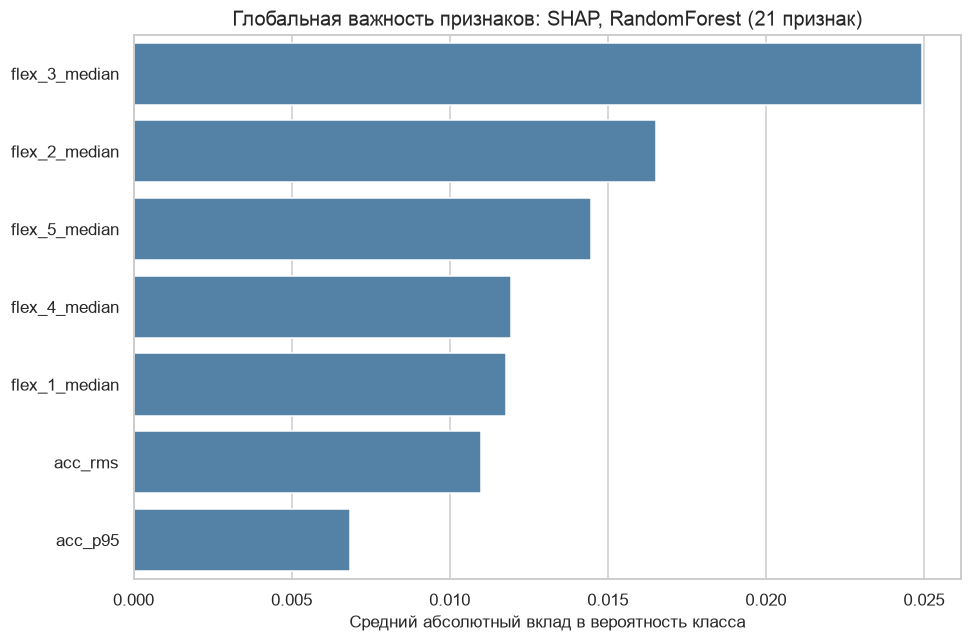

In [36]:
import shap

shap_model = ml_models[("RandomForest", "21 признак")]

# фиксируем подвыборку тестовых пользователей для ускорения расчета
# 104 – рандомное число сигналов тестовых пользователей, отсутствовавших при обучении
shap_table = letter_features.iloc[test_idx][feature_cols].sample(n=104, random_state=42)
explainer = shap.TreeExplainer(shap_model) # алгоритм SHAP, предназначенный для моделей на основе деревьев решений
shap_values = np.asarray(explainer.shap_values(shap_table, check_additivity=False))
if shap_values.shape == (len(encoder.classes_), len(shap_table), len(feature_cols)):
    shap_values = np.transpose(shap_values, (1, 2, 0))

shap_importance = pd.DataFrame({
    "Признак": feature_cols,
    "Средний |SHAP|": np.abs(shap_values).mean(axis=(0, 2)), # выводим в абсолютах
}).sort_values("Средний |SHAP|", ascending=False)

display(shap_importance.head(15).round(4))
plt.figure(figsize=(9, 6))
sns.barplot(data=shap_importance.head(7), x="Средний |SHAP|", y="Признак", color="steelblue")
plt.title("Глобальная важность признаков: SHAP, RandomForest (21 признак)")
plt.xlabel("Средний абсолютный вклад в вероятность класса")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Что показал SHAP.** В RandomForest наибольший средний абсолютный вклад дают медианы датчиков изгиба. Среди новых признаков выделяются наиболее значимые для предсказаний этой моделью `acc_rms` и `acc_p95`. Это согласуется с тем, что информация о движении полезно дополняет конфигурацию пальцев.

По результатам экспериментов наилучшее качество распознавания показала модель CNN-1D. В отличие от классических ML-моделей и MLP, она использует исходные временные ряды сенсорных сигналов без предварительной агрегации, что позволяет учитывать динамику выполнения жестов.

Также наблюдается снижение доли взаимных ошибок для некоторых пар похожих букв при переходе к более сложным моделям. Это указывает на потенциальную пользу учета временной структуры сигналов для различения жестов со схожей конфигурацией пальцев.

SHAP-анализ показал, что наиболее значимыми для RandomForest оказались медианные показания датчиков изгиба пальцев. Это подтверждает важность информации о конфигурации пальцев для распознавания букв, при этом характеристики движения кисти могут давать дополнительную информацию.